# 02 — Tiền xử lý, Temporal Split và Controlled Cold-start cho Yoochoose

Notebook này thực thi trọn vẹn pipeline tiền xử lý cho **Yoochoose** dựa trực tiếp trên các phát hiện EDA ở [`01_eda.ipynb`](01_eda.ipynb) và cấu hình chuẩn hóa tại [`configs/yoochoose/data.yaml`](../../configs/yoochoose/data.yaml).

Luồng xử lý gồm 13 bước tách biệt, mỗi bước có bảng kiểm chứng riêng và **không ghi đè bất kỳ dữ liệu nào của Diginetica**:

1. Thiết lập môi trường & nạp cấu hình YAML.
2. Đọc dữ liệu gốc `yoochoose-clicks.dat` bằng PyArrow.
3. Trích lát cắt gần nhất (`1/32` phiên, sạch category cuối tháng 09/2014).
4. Làm sạch, sắp xếp ổn định, loại trùng tuyệt đối & xuất `canonical_events.parquet`.
5. Chia temporal split theo cửa sổ 24 giờ neo vào `max_ts`.
6. Lọc fixed-point lần 1 trên Train (`len >= 2`, `freq >= 5`).
7. Phân giải Category chuẩn cấp item **chỉ từ Train trước holdout** (`1..12 > S_only(13) > brand_only(14) > unknown(0)`).
8. Chọn nhóm **Controlled Cold-start 20% (`Option B`)** phân tầng theo category.
9. Loại Controlled Cold khỏi Train, lọc fixed-point lần 2 & tách riêng **Natural Temporal Cold**.
10. Tạo `item_mapping.csv`, `category_mapping.csv`, `cold_items.csv` và nhóm độ phổ biến từ Final Train.
11. Xuất tập `events` (Warm & Full Audit) và sinh mẫu `All-prefix` / `Last-item`.
12. Chạy **16 kiểm định tự động** (anti-leakage, cold protocol, schema).
13. Lưu `dataset_statistics.json`, vẽ biểu đồ bàn giao cho giai đoạn huấn luyện 3 mô hình.

## 1. Thiết lập môi trường, đọc cấu hình `configs/yoochoose/data.yaml` và đường dẫn

In [1]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").is_file():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án DA-3.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from btl_k03.paths import get_dataset_paths, ensure_output_dirs
from btl_k03.utils import load_yaml, save_json

ensure_output_dirs("yoochoose")
YOO_PATHS = get_dataset_paths("yoochoose")
CFG = load_yaml(YOO_PATHS["config_dir"] / "data.yaml")

CLICKS_PATH = PROJECT_ROOT / CFG["raw_clicks_file"]
INTERIM_DIR = YOO_PATHS["interim_dir"]
PROCESSED_DIR = YOO_PATHS["processed_dir"]
TABLES_DIR = YOO_PATHS["tables_dir"]
FIGURES_DIR = YOO_PATHS["figures_dir"]

FRAC_DENOM = int(CFG["subsetting"]["fraction_denominator"])
MIN_SESS_LEN = int(CFG["filtering"]["min_session_length"])
MIN_ITEM_FREQ = int(CFG["filtering"]["min_item_frequency"])
VAL_DAYS = int(CFG["temporal_split"]["validation_days"])
TEST_DAYS = int(CFG["temporal_split"]["test_days"])
COLD_RATIO = float(CFG["cold_start"]["ratio"])
COLD_SEED = int(CFG["cold_start"]["seed"])
MIN_CAT_ITEMS_FOR_COLD = int(CFG["cold_start"]["min_pre_holdout_items_per_category"])
RARE_Q = float(CFG["popularity_groups"]["rare_quantile"])
POP_Q = float(CFG["popularity_groups"]["popular_quantile"])
PARQUET_COMP = str(CFG["exports"]["parquet_compression"])

attrition_rows: list[dict] = []


def record_stage(stage: str, frame: pd.DataFrame, note: str = "") -> None:
    n_ev = int(len(frame))
    n_se = int(frame["session_id"].nunique()) if n_ev else 0
    n_it = int(frame["item_id"].nunique()) if n_ev else 0
    attrition_rows.append(
        {
            "stage": stage,
            "events": n_ev,
            "sessions": n_se,
            "items": n_it,
            "prefix_target_examples": max(0, n_ev - n_se),
            "note": note,
        }
    )


print(f"Dataset              : {CFG['dataset']}")
print(f"Lát cắt              : 1/{FRAC_DENOM} phiên gần nhất")
print(f"Lọc fixed-point      : session_len >= {MIN_SESS_LEN}, item_freq >= {MIN_ITEM_FREQ}")
print(f"Temporal split (24h) : validation={VAL_DAYS} ngày, test={TEST_DAYS} ngày")
print(f"Controlled cold      : {COLD_RATIO*100:.0f}% (seed={COLD_SEED})")
print(f"Processed dir        : {PROCESSED_DIR}")

Dataset              : yoochoose
Lát cắt              : 1/32 phiên gần nhất
Lọc fixed-point      : session_len >= 2, item_freq >= 5
Temporal split (24h) : validation=1 ngày, test=1 ngày
Controlled cold      : 20% (seed=2024)
Processed dir        : D:\DA-3\data\processed\yoochoose


## 2. Đọc dữ liệu gốc `yoochoose-clicks.dat` bằng PyArrow & ghi nhận mốc Raw

In [2]:
t0 = time.perf_counter()

clicks_tbl = pv.read_csv(
    CLICKS_PATH,
    read_options=pv.ReadOptions(
        column_names=["session_id", "timestamp", "item_id", "category_raw"]
    ),
    convert_options=pv.ConvertOptions(
        column_types={
            "session_id": pa.int32(),
            "timestamp": pa.timestamp("ms", tz="UTC"),
            "item_id": pa.int32(),
            "category_raw": pa.dictionary(pa.int32(), pa.string()),
        }
    ),
)

raw_sess = clicks_tbl["session_id"].to_numpy(zero_copy_only=False)
raw_ts_ms = clicks_tbl["timestamp"].cast(pa.int64()).to_numpy(zero_copy_only=False)
raw_item = clicks_tbl["item_id"].to_numpy(zero_copy_only=False)
cat_chunked = clicks_tbl["category_raw"].combine_chunks()
cat_dict = cat_chunked.dictionary.to_pandas().astype(str).to_numpy()
raw_cat_idx = cat_chunked.indices.to_numpy(zero_copy_only=False)
del clicks_tbl, cat_chunked

n_raw_events = len(raw_sess)
n_raw_sessions = int(pd.Series(raw_sess).nunique())
n_raw_items = int(pd.Series(raw_item).nunique())
attrition_rows.append(
    {
        "stage": "01_raw_full_clicks",
        "events": n_raw_events,
        "sessions": n_raw_sessions,
        "items": n_raw_items,
        "prefix_target_examples": max(0, n_raw_events - n_raw_sessions),
        "note": "Toàn bộ file yoochoose-clicks.dat gốc",
    }
)

print(
    f"Đã nạp raw clicks trong {time.perf_counter()-t0:.2f}s | "
    f"Events: {n_raw_events:,} | Sessions: {n_raw_sessions:,} | Items: {n_raw_items:,}"
)

Đã nạp raw clicks trong 3.35s | Events: 33,003,944 | Sessions: 9,249,729 | Items: 52,739


## 3. Trích lát cắt gần nhất (`1/32` phiên) theo kết luận từ EDA

Dựa trên phát hiện ở `01_eda.ipynb`, lát cắt `1/32` nằm trọn trong cuối tháng 09/2014 (độ đầy đủ category ~95%) và có quy mô mẫu tương đương Diginetica.

In [3]:
tmp_sess_ts = pd.DataFrame({"session_id": raw_sess, "ts_ms": raw_ts_ms})
sess_last_ts = tmp_sess_ts.groupby("session_id", sort=False)["ts_ms"].max().sort_values()
del tmp_sess_ts

keep_n_sessions = max(1, len(sess_last_ts) // FRAC_DENOM)
keep_sids = set(sess_last_ts.index[-keep_n_sessions:])
global_max_ts_ms = int(sess_last_ts.iloc[-1])
subset_start_ts_ms = int(sess_last_ts.iloc[-keep_n_sessions])
del sess_last_ts

mask_sub = pd.Series(raw_sess).isin(keep_sids).to_numpy()
sub_df = pd.DataFrame(
    {
        "session_id": raw_sess[mask_sub].astype(np.int64),
        "ts_ms": raw_ts_ms[mask_sub].astype(np.int64),
        "item_id": raw_item[mask_sub].astype(np.int64),
        "category_raw": cat_dict[raw_cat_idx[mask_sub]],
        "row_order": np.flatnonzero(mask_sub).astype(np.int64),
    }
)
del raw_sess, raw_ts_ms, raw_item, raw_cat_idx, mask_sub

record_stage(
    f"02_recent_1_{FRAC_DENOM}_subset",
    sub_df,
    f"Từ {pd.Timestamp(subset_start_ts_ms, unit='ms', tz='UTC')} đến {pd.Timestamp(global_max_ts_ms, unit='ms', tz='UTC')}",
)

print(
    f"Lát cắt 1/{FRAC_DENOM}: {len(sub_df):,} events | "
    f"{sub_df['session_id'].nunique():,} sessions | "
    f"{sub_df['item_id'].nunique():,} items"
)
print(
    f"Khung thời gian: {pd.Timestamp(subset_start_ts_ms, unit='ms', tz='UTC')}  →  "
    f"{pd.Timestamp(global_max_ts_ms, unit='ms', tz='UTC')}"
)

Lát cắt 1/32: 968,054 events | 289,054 sessions | 21,337 items
Khung thời gian: 2014-09-22 12:42:33.836000+00:00  →  2014-09-30 02:59:59.430000+00:00


## 4. Làm sạch, chuẩn hóa thứ tự sự kiện & lưu bảng `canonical_events.parquet`

- Sắp xếp ổn định theo `(session_id, ts_ms, row_order)`.
- Loại bản ghi trùng tuyệt đối `(session_id, ts_ms, item_id)`, **giữ nguyên** click lặp ở timestamp khác.
- Loại phiên có độ dài `< 2`.
- Tạo cột `timeframe` (mili-giây từ đầu phiên) để tương thích 100% với `btl_k03.popularity_metrics`.

In [4]:
sub_df = sub_df.sort_values(
    ["session_id", "ts_ms", "row_order"], kind="mergesort"
).reset_index(drop=True)

if CFG["ordering"]["drop_exact_duplicate_events"]:
    before_dup = len(sub_df)
    sub_df = sub_df.drop_duplicates(
        subset=["session_id", "ts_ms", "item_id"], keep="first"
    ).reset_index(drop=True)
    dropped_exact_dups = before_dup - len(sub_df)
    record_stage("03_drop_exact_duplicates", sub_df, f"Loại {dropped_exact_dups:,} bản ghi trùng tuyệt đối")

sess_counts = sub_df["session_id"].value_counts()
sub_df = sub_df.loc[sub_df["session_id"].isin(sess_counts[sess_counts >= MIN_SESS_LEN].index)].reset_index(drop=True)
record_stage("04_filter_initial_len_ge_2", sub_df, f"Giữ phiên có >= {MIN_SESS_LEN} click")

sess_start_ms = sub_df.groupby("session_id")["ts_ms"].transform("min")
sess_end_ms = sub_df.groupby("session_id")["ts_ms"].transform("max")
sub_df["timeframe"] = (sub_df["ts_ms"] - sess_start_ms).astype(np.int64)
sub_df["session_last_ts_ms"] = sess_end_ms.astype(np.int64)
sub_df["event_date"] = pd.to_datetime(sub_df["ts_ms"], unit="ms", utc=True).dt.tz_localize(None)
sub_df["last_event_date"] = pd.to_datetime(sub_df["session_last_ts_ms"], unit="ms", utc=True).dt.tz_localize(None)
sub_df["event_position"] = sub_df.groupby("session_id").cumcount().astype(np.int64)

sub_df.to_parquet(INTERIM_DIR / "canonical_events.parquet", index=False, compression=PARQUET_COMP)
display(pd.DataFrame(attrition_rows))

,stage,events,sessions,items,prefix_target_examples,note
0,01_raw_full_clicks,33003944,9249729,52739,23754215,Toàn bộ file yoochoose-clicks.dat gốc
1,02_recent_1_32_subset,968054,289054,21337,679000,Từ 2014-09-22 12:42:33.836000+00:00 đến 2014-0...
2,03_drop_exact_duplicates,968054,289054,21337,679000,Loại 0 bản ghi trùng tuyệt đối
3,04_filter_initial_len_ge_2,893901,214901,20614,679000,Giữ phiên có >= 2 click


## 5. Temporal Split theo cửa sổ 24 giờ neo vào `max_ts`

Gán toàn bộ phiên theo `session_last_ts_ms` (không cắt phiên qua nửa đêm) và neo mốc 24h theo `max_ts` để tránh mẩu 3 giờ ngày `2014-09-30`.

In [5]:
DAY_MS = 86_400_000
test_start_ms = global_max_ts_ms - TEST_DAYS * DAY_MS
val_start_ms = test_start_ms - VAL_DAYS * DAY_MS

val_start_ts = pd.Timestamp(val_start_ms, unit="ms", tz="UTC")
test_start_ts = pd.Timestamp(test_start_ms, unit="ms", tz="UTC")
max_ts_utc = pd.Timestamp(global_max_ts_ms, unit="ms", tz="UTC")

sub_df["split"] = np.where(
    sub_df["session_last_ts_ms"] > test_start_ms,
    "test",
    np.where(sub_df["session_last_ts_ms"] > val_start_ms, "validation", "train"),
)

train_raw = sub_df.loc[sub_df["split"] == "train"].copy().reset_index(drop=True)
val_raw = sub_df.loc[sub_df["split"] == "validation"].copy().reset_index(drop=True)
test_raw = sub_df.loc[sub_df["split"] == "test"].copy().reset_index(drop=True)

record_stage("05a_temporal_train_raw", train_raw, f"session_last_ts <= {val_start_ts}")
record_stage("05b_temporal_val_raw", val_raw, f"{val_start_ts} < session_last_ts <= {test_start_ts}")
record_stage("05c_temporal_test_raw", test_raw, f"{test_start_ts} < session_last_ts <= {max_ts_utc}")

base_split_df = pd.DataFrame(
    [
        {"split": "train", "events": len(train_raw), "sessions": int(train_raw["session_id"].nunique()), "items": int(train_raw["item_id"].nunique())},
        {"split": "validation", "events": len(val_raw), "sessions": int(val_raw["session_id"].nunique()), "items": int(val_raw["item_id"].nunique())},
        {"split": "test", "events": len(test_raw), "sessions": int(test_raw["session_id"].nunique()), "items": int(test_raw["item_id"].nunique())},
    ]
)
base_split_df.to_csv(TABLES_DIR / "preprocessing_base_split_statistics.csv", index=False)
print(f"Validation window : ({val_start_ts}, {test_start_ts}]")
print(f"Test window       : ({test_start_ts}, {max_ts_utc}]")
display(base_split_df)

Validation window : (2014-09-28 02:59:59.430000+00:00, 2014-09-29 02:59:59.430000+00:00]
Test window       : (2014-09-29 02:59:59.430000+00:00, 2014-09-30 02:59:59.430000+00:00]


,split,events,sessions,items
0,train,764225,187175,20103
1,validation,58309,12386,6417
2,test,71367,15340,6828


## 6. Lọc fixed-point lần 1 trên tập Train (`len >= 2`, `freq >= 5`)

Chỉ dùng dữ liệu Train để xác định tập sản phẩm đủ hỗ trợ trước khi holdout cold-start, tuyệt đối không dùng thông tin Validation/Test.

In [6]:
def fixed_point_filter(frame: pd.DataFrame, min_len: int, min_freq: int) -> tuple[pd.DataFrame, int]:
    d = frame.copy()
    iters = 0
    while True:
        iters += 1
        prev = len(d)
        sc = d["session_id"].value_counts()
        d = d.loc[d["session_id"].isin(sc[sc >= min_len].index)]
        ic = d["item_id"].value_counts()
        d = d.loc[d["item_id"].isin(ic[ic >= min_freq].index)]
        if len(d) == prev:
            break
    return d.reset_index(drop=True), iters


train_pre_cold, fp1_iters = fixed_point_filter(train_raw, MIN_SESS_LEN, MIN_ITEM_FREQ)
record_stage(
    "06_train_pre_holdout_fixed_point",
    train_pre_cold,
    f"Hội tụ sau {fp1_iters} vòng (len>={MIN_SESS_LEN}, freq>={MIN_ITEM_FREQ})",
)

print(
    f"Hội tụ sau {fp1_iters} vòng | Train pre-holdout: "
    f"{len(train_pre_cold):,} events | "
    f"{train_pre_cold['session_id'].nunique():,} sessions | "
    f"{train_pre_cold['item_id'].nunique():,} items"
)

Hội tụ sau 5 vòng | Train pre-holdout: 741,697 events | 182,184 sessions | 10,582 items


## 7. Phân giải Category chuẩn cấp item (CHỈ từ Train trước holdout)

Áp dụng quy tắc ưu tiên rút ra từ EDA (`1..12` > `S_only=13` > `brand_only=14` > `unknown=0`), đồng thời lưu cờ `has_regular_category`, `ever_special_offer` và `special_offer_click_share`.

In [7]:
REG_STR_SET = {str(i) for i in CFG["category_resolution"]["regular_category_ids"]}
CODE_S_ONLY = int(CFG["category_resolution"]["special_offer_only_code"])
CODE_BRAND_ONLY = int(CFG["category_resolution"]["brand_only_code"])
CODE_UNKNOWN = int(CFG["category_resolution"]["unknown_code"])

cat_raw_s = train_pre_cold["category_raw"].astype(str)
is_reg_ev = cat_raw_s.isin(REG_STR_SET)
is_s_ev = cat_raw_s.eq("S")
is_zero_ev = cat_raw_s.eq("0")
is_brand_ev = (~is_reg_ev) & (~is_s_ev) & (~is_zero_ev)

reg_mode_df = (
    train_pre_cold.loc[is_reg_ev, ["item_id"]]
    .assign(reg_cat=cat_raw_s.loc[is_reg_ev].astype(np.int64))
    .groupby(["item_id", "reg_cat"], sort=True)
    .size()
    .reset_index(name="cnt")
    .sort_values(["item_id", "cnt", "reg_cat"], ascending=[True, False, True])
    .drop_duplicates("item_id")
    .set_index("item_id")["reg_cat"]
)

item_total_pre = train_pre_cold.groupby("item_id").size()
item_s_clicks = train_pre_cold.loc[is_s_ev].groupby("item_id").size().reindex(item_total_pre.index, fill_value=0)
item_brand_clicks = train_pre_cold.loc[is_brand_ev].groupby("item_id").size().reindex(item_total_pre.index, fill_value=0)

pre_catalog = pd.DataFrame(
    {
        "item_id": item_total_pre.index.astype(np.int64),
        "pre_holdout_train_frequency": item_total_pre.to_numpy(dtype=np.int64),
        "reg_cat": item_total_pre.index.map(reg_mode_df),
        "s_clicks": item_s_clicks.to_numpy(dtype=np.int64),
        "brand_clicks": item_brand_clicks.to_numpy(dtype=np.int64),
    }
)

conditions = [
    pre_catalog["reg_cat"].notna(),
    pre_catalog["s_clicks"] > 0,
    pre_catalog["brand_clicks"] > 0,
]
pre_catalog["category_id"] = np.select(
    conditions,
    [pre_catalog["reg_cat"].fillna(-1).astype(np.int64), CODE_S_ONLY, CODE_BRAND_ONLY],
    default=CODE_UNKNOWN,
).astype(np.int64)
pre_catalog["category_source"] = np.select(
    conditions,
    ["regular_1_12", "special_offer_only", "brand_only"],
    default="unknown_0",
)
pre_catalog["has_regular_category"] = pre_catalog["category_source"].eq("regular_1_12")
pre_catalog["ever_special_offer"] = pre_catalog["s_clicks"] > 0
pre_catalog["special_offer_click_share"] = (
    pre_catalog["s_clicks"] / pre_catalog["pre_holdout_train_frequency"]
).astype(np.float64)

cat_res_summary = (
    pre_catalog.groupby("category_source")
    .agg(items=("item_id", "size"), train_events=("pre_holdout_train_frequency", "sum"))
    .reset_index()
)
cat_res_summary["item_share_pct"] = cat_res_summary["items"] / len(pre_catalog) * 100.0
cat_res_summary["event_share_pct"] = (
    cat_res_summary["train_events"] / pre_catalog["pre_holdout_train_frequency"].sum() * 100.0
)
cat_res_summary.to_csv(TABLES_DIR / "preprocessing_category_resolution.csv", index=False)
display(cat_res_summary)

,category_source,items,train_events,item_share_pct,event_share_pct
0,brand_only,3,16,0.0284,0.0022
1,regular_1_12,9322,325019,88.0930,43.8210
2,special_offer_only,555,390255,5.2448,52.6165
3,unknown_0,702,26407,6.6339,3.5603


## 8. Tạo nhóm Controlled Cold-start 20% (`Option B`) phân tầng theo Category

Chọn đúng `round(20% * N_pre_holdout)` item với `seed = 2024`, phân bổ tỷ lệ theo từng category có `>= 5` item và bảo đảm mỗi category giữ tối thiểu 1 warm peer.

In [8]:
rng = np.random.default_rng(COLD_SEED)
n_pre_items = len(pre_catalog)
target_cold_count = int(round(COLD_RATIO * n_pre_items))

cat_sizes = pre_catalog.groupby("category_id").size().sort_index()
eligible_cats = cat_sizes[cat_sizes >= MIN_CAT_ITEMS_FOR_COLD]
max_per_cat = (eligible_cats - 1).to_dict()

raw_quota = eligible_cats / eligible_cats.sum() * target_cold_count
floor_quota = np.floor(raw_quota).astype(int)
for c in floor_quota.index:
    floor_quota.loc[c] = min(int(floor_quota.loc[c]), max_per_cat[c])

remainder = target_cold_count - int(floor_quota.sum())
if remainder > 0:
    for c in (raw_quota - floor_quota).sort_values(ascending=False).index:
        if remainder == 0:
            break
        if floor_quota.loc[c] < max_per_cat[c]:
            floor_quota.loc[c] += 1
            remainder -= 1

assert int(floor_quota.sum()) == target_cold_count, "Không phân bổ đủ số controlled cold!"

controlled_cold_ids_list = []
for cat_id in sorted(floor_quota.index):
    q = int(floor_quota.loc[cat_id])
    if q <= 0:
        continue
    pool = np.sort(pre_catalog.loc[pre_catalog["category_id"] == cat_id, "item_id"].to_numpy(dtype=np.int64))
    controlled_cold_ids_list.append(rng.choice(pool, size=q, replace=False))

controlled_cold_ids = set(np.concatenate(controlled_cold_ids_list).tolist())
assert len(controlled_cold_ids) == target_cold_count

cold_by_cat_df = pd.DataFrame(
    {
        "category_id": eligible_cats.index,
        "pre_holdout_items": eligible_cats.values,
        "controlled_cold_items": [int(floor_quota.loc[c]) for c in eligible_cats.index],
    }
)
cold_by_cat_df["cold_ratio_pct"] = cold_by_cat_df["controlled_cold_items"] / cold_by_cat_df["pre_holdout_items"] * 100.0
print(f"Đã chọn {len(controlled_cold_ids):,} / {n_pre_items:,} item ({len(controlled_cold_ids)/n_pre_items*100:.4f}%) làm Controlled Cold.")
display(cold_by_cat_df)

Đã chọn 2,116 / 10,582 item (19.9962%) làm Controlled Cold.


,category_id,pre_holdout_items,controlled_cold_items,cold_ratio_pct
0,0,702,140,19.9430
1,1,3130,626,20.0000
2,2,2226,445,19.9910
3,3,658,132,20.0608
4,4,545,109,20.0000
5,5,588,118,20.0680
6,6,535,107,20.0000
7,7,600,120,20.0000
8,8,533,107,20.0750
9,9,312,62,19.8718


## 9. Loại Controlled Cold khỏi Train, lọc fixed-point lần 2 & tách riêng Natural Temporal Cold

In [9]:
train_after_drop = train_pre_cold.loc[~train_pre_cold["item_id"].isin(controlled_cold_ids)].reset_index(drop=True)
record_stage("07_train_after_drop_controlled_cold", train_after_drop, f"Loại {len(controlled_cold_ids):,} controlled cold items")

train_final, fp2_iters = fixed_point_filter(train_after_drop, MIN_SESS_LEN, MIN_ITEM_FREQ)
record_stage("08_train_final_warm", train_final, f"Fixed-point lần 2 hội tụ sau {fp2_iters} vòng")

final_warm_ids = set(train_final["item_id"].unique())
pre_holdout_ids = set(pre_catalog["item_id"].unique())
post_holdout_attrition_ids = pre_holdout_ids - controlled_cold_ids - final_warm_ids

train_raw_ids = set(train_raw["item_id"].unique())
future_events_all = pd.concat([val_raw, test_raw], ignore_index=True)
future_item_freq = future_events_all.groupby("item_id").size()
natural_cold_ids = set(future_events_all["item_id"].unique()) - train_raw_ids

cold_summary = pd.DataFrame(
    [
        {"metric": "pre_holdout_filtered_train_items", "value": n_pre_items},
        {"metric": "controlled_cold_items", "value": len(controlled_cold_ids)},
        {"metric": "controlled_cold_ratio_actual", "value": len(controlled_cold_ids) / n_pre_items},
        {"metric": "final_trainable_warm_items", "value": len(final_warm_ids)},
        {"metric": "post_holdout_attrition_items", "value": len(post_holdout_attrition_ids)},
        {"metric": "natural_temporal_cold_items", "value": len(natural_cold_ids)},
        {"metric": "model_catalog_items_warm_plus_controlled_cold", "value": len(final_warm_ids) + len(controlled_cold_ids)},
    ]
)
cold_summary.to_csv(TABLES_DIR / "preprocessing_cold_start_summary.csv", index=False)
display(cold_summary)

,metric,value
0,pre_holdout_filtered_train_items,"10,582.0000"
1,controlled_cold_items,"2,116.0000"
2,controlled_cold_ratio_actual,0.2000
3,final_trainable_warm_items,"8,326.0000"
4,post_holdout_attrition_items,140.0000
5,natural_temporal_cold_items,511.0000
6,model_catalog_items_warm_plus_controlled_cold,"10,442.0000"


## 10. Xây dựng `item_mapping.csv`, `category_mapping.csv`, `cold_items.csv` & nhóm độ phổ biến từ Final Train

In [10]:
model_catalog_ids = final_warm_ids | controlled_cold_ids
final_train_freq = train_final.groupby("item_id").size()

item_mapping = (
    pre_catalog.loc[pre_catalog["item_id"].isin(model_catalog_ids)]
    .sort_values("item_id", kind="mergesort")
    .reset_index(drop=True)
)
item_mapping.insert(0, "internal_item_id", np.arange(1, len(item_mapping) + 1, dtype=np.int64))
item_mapping["train_frequency"] = item_mapping["item_id"].map(final_train_freq).fillna(0).astype(np.int64)
item_mapping["future_frequency"] = item_mapping["item_id"].map(future_item_freq).fillna(0).astype(np.int64)
item_mapping["is_controlled_cold"] = item_mapping["item_id"].isin(controlled_cold_ids)
item_mapping["is_trainable_warm"] = ~item_mapping["is_controlled_cold"]
item_mapping["candidate_for_main_evaluation"] = item_mapping["is_trainable_warm"]

warm_freqs = item_mapping.loc[item_mapping["is_trainable_warm"], "train_frequency"]
rare_max_freq = int(np.quantile(warm_freqs, RARE_Q))
pop_min_freq = int(np.quantile(warm_freqs, POP_Q))
if pop_min_freq <= rare_max_freq:
    pop_min_freq = rare_max_freq + 1

item_mapping["popularity_group"] = np.where(
    item_mapping["is_controlled_cold"],
    "cold",
    np.where(
        item_mapping["train_frequency"] <= rare_max_freq,
        "rare",
        np.where(item_mapping["train_frequency"] >= pop_min_freq, "popular", "medium"),
    ),
)

unique_cats = np.sort(item_mapping["category_id"].unique())
category_mapping = pd.DataFrame(
    {
        "internal_category_id": np.arange(1, len(unique_cats) + 1, dtype=np.int64),
        "category_id": unique_cats.astype(np.int64),
    }
)
cat_to_internal = dict(zip(category_mapping["category_id"], category_mapping["internal_category_id"]))
item_mapping["internal_category_id"] = item_mapping["category_id"].map(cat_to_internal).astype(np.int64)

item_mapping = item_mapping[
    [
        "internal_item_id", "item_id", "category_id", "pre_holdout_train_frequency",
        "train_frequency", "future_frequency", "is_controlled_cold", "is_trainable_warm",
        "popularity_group", "candidate_for_main_evaluation", "internal_category_id",
        "category_source", "has_regular_category", "ever_special_offer", "special_offer_click_share",
    ]
]
item_mapping.to_csv(PROCESSED_DIR / "item_mapping.csv", index=False)
category_mapping.to_csv(PROCESSED_DIR / "category_mapping.csv", index=False)

item_mapping[
    [
        "item_id", "internal_item_id", "category_id", "train_frequency",
        "popularity_group", "is_controlled_cold", "candidate_for_main_evaluation",
        "has_regular_category", "ever_special_offer",
    ]
].to_csv(PROCESSED_DIR / "popularity_groups.csv", index=False)

controlled_cold_df = item_mapping.loc[
    item_mapping["is_controlled_cold"],
    ["item_id", "internal_item_id", "category_id", "pre_holdout_train_frequency", "train_frequency", "future_frequency"],
].copy()
controlled_cold_df["cold_type"] = "controlled_option_b"
controlled_cold_df["selection_seed"] = COLD_SEED
controlled_cold_df["in_model_catalog"] = True

nat_cold_df = pd.DataFrame({"item_id": sorted(natural_cold_ids)})
nat_cold_df["internal_item_id"] = pd.Series([pd.NA] * len(nat_cold_df), dtype="Int64")
nat_cold_df["category_id"] = -1
nat_cold_df["pre_holdout_train_frequency"] = 0
nat_cold_df["train_frequency"] = 0
nat_cold_df["future_frequency"] = nat_cold_df["item_id"].map(future_item_freq).fillna(0).astype(np.int64)
nat_cold_df["cold_type"] = "natural_temporal"
nat_cold_df["selection_seed"] = pd.NA
nat_cold_df["in_model_catalog"] = False

pd.concat([controlled_cold_df, nat_cold_df], ignore_index=True).to_csv(PROCESSED_DIR / "cold_items.csv", index=False)

pop_summary = (
    item_mapping.groupby("popularity_group")
    .agg(
        items=("item_id", "size"),
        min_freq=("train_frequency", "min"),
        median_freq=("train_frequency", "median"),
        max_freq=("train_frequency", "max"),
        train_events=("train_frequency", "sum"),
        regular_cat_pct=("has_regular_category", lambda s: float(s.mean() * 100.0)),
        special_offer_pct=("ever_special_offer", lambda s: float(s.mean() * 100.0)),
    )
    .reindex(["popular", "medium", "rare", "cold"])
    .reset_index()
)
pop_summary.to_csv(TABLES_DIR / "preprocessing_popularity_group_summary.csv", index=False)
print(f"Ngưỡng tần suất warm: rare <= {rare_max_freq}, medium = [{rare_max_freq+1}..{pop_min_freq-1}], popular >= {pop_min_freq}")
display(pop_summary)

Ngưỡng tần suất warm: rare <= 7, medium = [8..41], popular >= 42


,popularity_group,items,min_freq,median_freq,max_freq,train_events,regular_cat_pct,special_offer_pct
0,popular,1684,42,89.0000,10181,478324,68.5867,30.1663
1,medium,4695,8,15.0000,41,81201,91.8850,1.9169
2,rare,1947,5,6.0000,7,11430,95.4289,0.3082
3,cold,2116,0,0.0000,0,0,88.1380,7.5142


## 11. Xuất các tập `events` (Warm & Full Audit) và sinh mẫu `All-prefix` / `Last-item`

Schema của `*_events.parquet`, `*_events_full.parquet` và `*_examples.parquet` tương thích 100% với `SessionPrefixDataset` và `compute_cold_start_test_diagnostic` trong `src/btl_k03/`.

In [11]:
item_to_internal = dict(zip(item_mapping["item_id"], item_mapping["internal_item_id"]))
item_to_cat = dict(zip(item_mapping["item_id"], item_mapping["category_id"]))
item_to_group = dict(zip(item_mapping["item_id"], item_mapping["popularity_group"]))


def annotate_events(frame: pd.DataFrame, keep_warm_only: bool) -> pd.DataFrame:
    d = frame.copy()
    if keep_warm_only:
        d = d.loc[d["item_id"].isin(final_warm_ids)].copy()
        sc = d["session_id"].value_counts()
        d = d.loc[d["session_id"].isin(sc[sc >= MIN_SESS_LEN].index)].copy()

    d = d.sort_values(["session_id", "timeframe", "row_order"], kind="mergesort").reset_index(drop=True)
    d["category_id"] = d["item_id"].map(item_to_cat).fillna(-1).astype(np.int64)
    if keep_warm_only:
        d["internal_item_id"] = d["item_id"].map(item_to_internal).astype(np.int64)
    else:
        d["internal_item_id"] = d["item_id"].map(item_to_internal).astype("Int64")

    d["is_controlled_cold"] = d["item_id"].isin(controlled_cold_ids)
    d["is_natural_cold"] = d["item_id"].isin(natural_cold_ids)
    d["popularity_group"] = d["item_id"].map(item_to_group).fillna(
        pd.Series(np.where(d["is_natural_cold"], "natural_cold", "filtered_out"), index=d.index)
    )
    d["sequence_position"] = d.groupby("session_id").cumcount().astype(np.int64)
    return d


train_events = annotate_events(train_final, keep_warm_only=True)
val_events = annotate_events(val_raw, keep_warm_only=True)
test_events = annotate_events(test_raw, keep_warm_only=True)
val_events_full = annotate_events(val_raw, keep_warm_only=False)
test_events_full = annotate_events(test_raw, keep_warm_only=False)

record_stage("09a_validation_final_warm", val_events, "Chỉ giữ final warm items & session_len >= 2")
record_stage("09b_test_final_warm", test_events, "Chỉ giữ final warm items & session_len >= 2")

train_events.to_parquet(PROCESSED_DIR / "train_events.parquet", index=False, compression=PARQUET_COMP)
val_events.to_parquet(PROCESSED_DIR / "validation_events.parquet", index=False, compression=PARQUET_COMP)
test_events.to_parquet(PROCESSED_DIR / "test_events.parquet", index=False, compression=PARQUET_COMP)
val_events_full.to_parquet(PROCESSED_DIR / "validation_events_full.parquet", index=False, compression=PARQUET_COMP)
test_events_full.to_parquet(PROCESSED_DIR / "test_events_full.parquet", index=False, compression=PARQUET_COMP)


def build_prefix_examples(events_df: pd.DataFrame, split_name: str, max_prefix_len: int = 50) -> tuple[pd.DataFrame, pd.DataFrame]:
    sids = events_df["session_id"].to_numpy(dtype=np.int64)
    int_ids = events_df["internal_item_id"].to_numpy(dtype=np.int64)
    raw_ids = events_df["item_id"].to_numpy(dtype=np.int64)
    groups = events_df["popularity_group"].astype(str).to_numpy()

    change_idx = np.flatnonzero(np.concatenate([[True], sids[1:] != sids[:-1], [True]]))

    all_sids, all_prefixes, all_lens, all_t_int, all_t_raw, all_t_grp = [], [], [], [], [], []
    last_sids, last_prefixes, last_lens, last_t_int, last_t_raw, last_t_grp = [], [], [], [], [], []

    for start, end in zip(change_idx[:-1], change_idx[1:]):
        seq_len = end - start
        if seq_len < 2:
            continue
        sid = int(sids[start])
        seq_int = int_ids[start:end].tolist()
        for pos in range(1, seq_len):
            pref = seq_int[max(0, pos - max_prefix_len) : pos]
            all_sids.append(sid)
            all_prefixes.append(pref)
            all_lens.append(len(pref))
            all_t_int.append(int(int_ids[start + pos]))
            all_t_raw.append(int(raw_ids[start + pos]))
            all_t_grp.append(groups[start + pos])

        pref_last = seq_int[max(0, seq_len - 1 - max_prefix_len) : seq_len - 1]
        last_sids.append(sid)
        last_prefixes.append(pref_last)
        last_lens.append(len(pref_last))
        last_t_int.append(int(int_ids[end - 1]))
        last_t_raw.append(int(raw_ids[end - 1]))
        last_t_grp.append(groups[end - 1])

    all_df = pd.DataFrame(
        {
            "session_id": np.asarray(all_sids, dtype=np.int64),
            "split": split_name,
            "prefix_items": all_prefixes,
            "prefix_length": np.asarray(all_lens, dtype=np.int64),
            "target_internal_item_id": np.asarray(all_t_int, dtype=np.int64),
            "target_item_id": np.asarray(all_t_raw, dtype=np.int64),
            "target_popularity_group": all_t_grp,
        }
    )
    last_df = pd.DataFrame(
        {
            "session_id": np.asarray(last_sids, dtype=np.int64),
            "split": split_name,
            "prefix_items": last_prefixes,
            "prefix_length": np.asarray(last_lens, dtype=np.int64),
            "target_internal_item_id": np.asarray(last_t_int, dtype=np.int64),
            "target_item_id": np.asarray(last_t_raw, dtype=np.int64),
            "target_popularity_group": last_t_grp,
        }
    )
    return all_df, last_df


t_ex = time.perf_counter()
train_examples, train_last_examples = build_prefix_examples(train_events, "train")
val_examples, val_last_examples = build_prefix_examples(val_events, "validation")
test_examples, test_last_examples = build_prefix_examples(test_events, "test")

train_examples.to_parquet(PROCESSED_DIR / "train_examples.parquet", index=False, compression=PARQUET_COMP)
val_examples.to_parquet(PROCESSED_DIR / "validation_examples.parquet", index=False, compression=PARQUET_COMP)
test_examples.to_parquet(PROCESSED_DIR / "test_examples.parquet", index=False, compression=PARQUET_COMP)
train_last_examples.to_parquet(PROCESSED_DIR / "train_last_item_examples.parquet", index=False, compression=PARQUET_COMP)
val_last_examples.to_parquet(PROCESSED_DIR / "validation_last_item_examples.parquet", index=False, compression=PARQUET_COMP)
test_last_examples.to_parquet(PROCESSED_DIR / "test_last_item_examples.parquet", index=False, compression=PARQUET_COMP)

example_summary = pd.DataFrame(
    [
        {"split": "train", "sessions": int(train_events["session_id"].nunique()), "all_prefix_examples": len(train_examples), "last_item_examples": len(train_last_examples)},
        {"split": "validation", "sessions": int(val_events["session_id"].nunique()), "all_prefix_examples": len(val_examples), "last_item_examples": len(val_last_examples)},
        {"split": "test", "sessions": int(test_events["session_id"].nunique()), "all_prefix_examples": len(test_examples), "last_item_examples": len(test_last_examples)},
    ]
)
example_summary.to_csv(TABLES_DIR / "preprocessing_example_summary.csv", index=False)
print(f"Đã sinh & xuất toàn bộ examples trong {time.perf_counter()-t_ex:.2f}s")
display(example_summary)

Đã sinh & xuất toàn bộ examples trong 2.20s


,split,sessions,all_prefix_examples,last_item_examples
0,train,150666,420289,150666
1,validation,10578,34645,10578
2,test,12660,41585,12660


## 12. Audit tự động 16 điều kiện chống leakage, cold protocol và toàn vẹn schema

In [12]:
tr_sids = set(train_events["session_id"].unique())
va_sids = set(val_events["session_id"].unique())
te_sids = set(test_events["session_id"].unique())
cold_cats = set(item_mapping.loc[item_mapping["is_controlled_cold"], "category_id"])
warm_cats = set(item_mapping.loc[item_mapping["is_trainable_warm"], "category_id"])

audits = [
    ("sessions_disjoint_train_val", tr_sids.isdisjoint(va_sids)),
    ("sessions_disjoint_train_test", tr_sids.isdisjoint(te_sids)),
    ("sessions_disjoint_val_test", va_sids.isdisjoint(te_sids)),
    ("temporal_boundary_train_lt_val", int(train_events["session_last_ts_ms"].max()) <= val_start_ms),
    ("temporal_boundary_val_in_window", int(val_events["session_last_ts_ms"].min()) > val_start_ms and int(val_events["session_last_ts_ms"].max()) <= test_start_ms),
    ("temporal_boundary_test_gt_val", int(test_events["session_last_ts_ms"].min()) > test_start_ms),
    ("all_sessions_len_ge_2", all(int(df_x.groupby("session_id").size().min()) >= 2 for df_x in (train_events, val_events, test_events))),
    ("events_ordered_within_session", all(df_x.index.equals(df_x.sort_values(["session_id", "timeframe", "row_order"], kind="mergesort").index) for df_x in (train_events, val_events, test_events))),
    ("controlled_cold_exact_20pct", len(controlled_cold_ids) == round(COLD_RATIO * n_pre_items)),
    ("zero_cold_leakage_in_train_events", controlled_cold_ids.isdisjoint(set(train_events["item_id"]))),
    ("zero_cold_leakage_in_train_targets", controlled_cold_ids.isdisjoint(set(train_examples["target_item_id"]))),
    ("val_test_warm_only_items", set(val_events["item_id"]).issubset(final_warm_ids) and set(test_events["item_id"]).issubset(final_warm_ids)),
    ("every_cold_category_has_warm_peer", cold_cats.issubset(warm_cats)),
    ("internal_item_id_1_to_N_unique", item_mapping["internal_item_id"].is_unique and int(item_mapping["internal_item_id"].min()) == 1 and int(item_mapping["internal_item_id"].max()) == len(item_mapping)),
    ("train_freq_sum_equals_train_events", int(item_mapping["train_frequency"].sum()) == len(train_events)),
    ("no_missing_category_in_mapping", not item_mapping["category_id"].isna().any() and set(item_mapping["category_id"]).issubset(set(category_mapping["category_id"]))),
]

audit_df = pd.DataFrame(audits, columns=["check", "passed"])
audit_df.to_csv(TABLES_DIR / "preprocessing_checks.csv", index=False)
display(audit_df)

all_passed = bool(audit_df["passed"].all())
assert all_passed, f"Có audit thất bại: {audit_df.loc[~audit_df['passed'], 'check'].tolist()}"
print(f"Tất cả {len(audit_df)}/{len(audit_df)} kiểm định đều ĐẠT.")

,check,passed
0,sessions_disjoint_train_val,True
1,sessions_disjoint_train_test,True
2,sessions_disjoint_val_test,True
3,temporal_boundary_train_lt_val,True
4,temporal_boundary_val_in_window,True
5,temporal_boundary_test_gt_val,True
6,all_sessions_len_ge_2,True
7,events_ordered_within_session,True
8,controlled_cold_exact_20pct,True
9,zero_cold_leakage_in_train_events,True


Tất cả 16/16 kiểm định đều ĐẠT.


## 13. Xuất `dataset_statistics.json`, biểu đồ bàn giao & tóm tắt cuối cùng

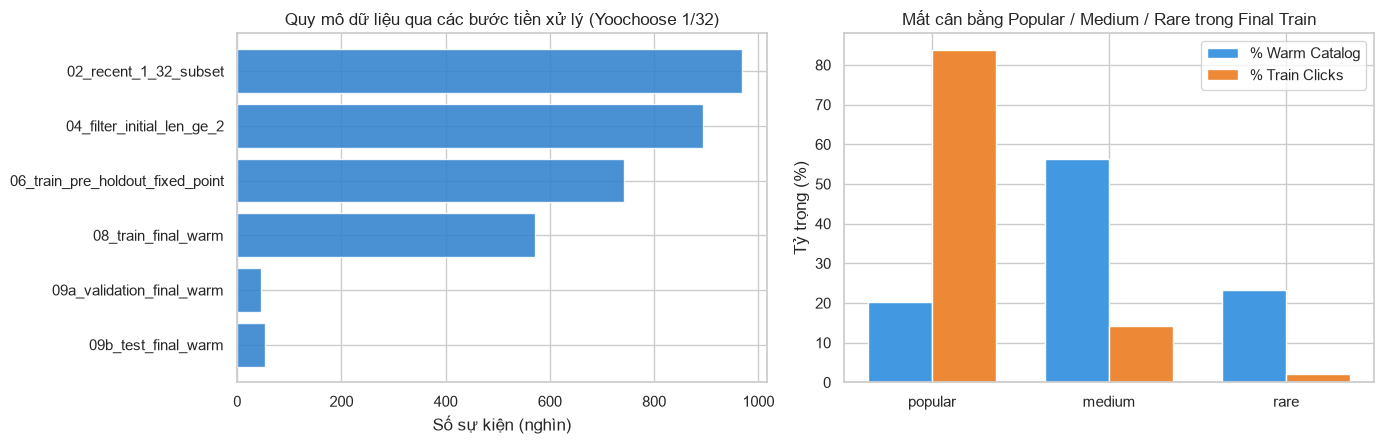

HOÀN TẤT TIỀN XỬ LÝ YOOCHOOSE (16/16 audits PASSED) -> D:\DA-3\data\processed\yoochoose


In [13]:
attrition_df = pd.DataFrame(attrition_rows)
attrition_df.to_csv(TABLES_DIR / "preprocessing_attrition_official.csv", index=False)

stats_payload = {
    "dataset": "yoochoose",
    "subset_fraction": f"1/{FRAC_DENOM}",
    "subset_start_utc": str(pd.Timestamp(subset_start_ts_ms, unit="ms", tz="UTC")),
    "data_end_utc": str(max_ts_utc),
    "validation_start_utc": str(val_start_ts),
    "test_start_utc": str(test_start_ts),
    "min_session_length": MIN_SESS_LEN,
    "min_item_frequency": MIN_ITEM_FREQ,
    "controlled_cold_ratio_requested": COLD_RATIO,
    "controlled_cold_ratio_actual": len(controlled_cold_ids) / n_pre_items,
    "controlled_cold_seed": COLD_SEED,
    "rare_frequency_max": rare_max_freq,
    "popular_frequency_min": pop_min_freq,
    "model_catalog_size": int(len(item_mapping)),
    "warm_catalog_size": int(item_mapping["is_trainable_warm"].sum()),
    "controlled_cold_size": int(item_mapping["is_controlled_cold"].sum()),
    "regular_1_12_item_share_pct": float(item_mapping["has_regular_category"].mean() * 100.0),
    "special_offer_item_share_pct": float(item_mapping["ever_special_offer"].mean() * 100.0),
    "final_splits": [
        {
            "stage": "train",
            "events": int(len(train_events)),
            "sessions": int(train_events["session_id"].nunique()),
            "items": int(train_events["item_id"].nunique()),
            "categories": int(train_events["category_id"].nunique()),
            "prefix_target_examples": int(len(train_examples)),
        },
        {
            "stage": "validation_warm",
            "events": int(len(val_events)),
            "sessions": int(val_events["session_id"].nunique()),
            "items": int(val_events["item_id"].nunique()),
            "categories": int(val_events["category_id"].nunique()),
            "prefix_target_examples": int(len(val_examples)),
        },
        {
            "stage": "test_warm",
            "events": int(len(test_events)),
            "sessions": int(test_events["session_id"].nunique()),
            "items": int(test_events["item_id"].nunique()),
            "categories": int(test_events["category_id"].nunique()),
            "prefix_target_examples": int(len(test_examples)),
        },
    ],
    "examples": example_summary.to_dict(orient="records"),
    "audit_passed": all_passed,
}

save_json(stats_payload, PROCESSED_DIR / "dataset_statistics.json")
save_json(CFG, PROCESSED_DIR / "preprocessing_config.json")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
plot_stages = attrition_df.loc[attrition_df["stage"].isin([
    f"02_recent_1_{FRAC_DENOM}_subset",
    "04_filter_initial_len_ge_2",
    "06_train_pre_holdout_fixed_point",
    "08_train_final_warm",
    "09a_validation_final_warm",
    "09b_test_final_warm",
])]
axes[0].barh(plot_stages["stage"], plot_stages["events"] / 1e3, color="#3182ce", alpha=0.88)
axes[0].invert_yaxis()
axes[0].set_xlabel("Số sự kiện (nghìn)")
axes[0].set_title(f"Quy mô dữ liệu qua các bước tiền xử lý (Yoochoose 1/{FRAC_DENOM})")

warm_pop = pop_summary.loc[pop_summary["popularity_group"] != "cold"]
x = np.arange(len(warm_pop))
w = 0.36
axes[1].bar(x - w / 2, warm_pop["items"] / warm_pop["items"].sum() * 100, w, label="% Warm Catalog", color="#4299e1")
axes[1].bar(x + w / 2, warm_pop["train_events"] / warm_pop["train_events"].sum() * 100, w, label="% Train Clicks", color="#ed8936")
axes[1].set_xticks(x)
axes[1].set_xticklabels(warm_pop["popularity_group"])
axes[1].set_ylabel("Tỷ trọng (%)")
axes[1].set_title("Mất cân bằng Popular / Medium / Rare trong Final Train")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "preprocessing_attrition_and_groups.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"HOÀN TẤT TIỀN XỬ LÝ YOOCHOOSE (16/16 audits PASSED) -> {PROCESSED_DIR}")